# Assignment 8 - English-to-Hindi Neural Machine Translation

**Name:** Tanu Meena  
**Roll number:** U23AI076  
**Library:** OpenNMT-py 3.5.1  
**Dataset:** AI4Bharat BPCC, `ilci/hin_Deva.tsv`

This solution trains an encoder-decoder Transformer from scratch and evaluates
Hindi translations with SacreBLEU. It follows Assignment 3's length-aware split
and subword training approach, and Labs 6 and 7's explanations, saved predictions,
model checkpoints, tables, and plots. The earlier monolingual IndicCorpV2 data
cannot supply aligned English-Hindi pairs, so this lab uses the required ILCI data.

Run the cells in order. BPCC requires accepting access on its Hugging Face page
and logging in locally with `hf auth login`. Keep credentials out of the notebook.
OpenNMT uses the local Python 3.12 runtime when available; otherwise it uses
`ONMT_PYTHON` or the current interpreter. The notebook itself can run in the
existing Python 3.14 kernel on this computer.

## 1. Setup and fixed experiment settings

The complete cleaned corpus is split 80/10/10 within each length bin into
training, validation, and test data. Validation is carved out to select the
checkpoint without inspecting test BLEU. No corpus subsampling is performed.
The small model makes CPU training possible. More training steps and a larger
model are reasonable later experiments, but must be set before test evaluation.

In [1]:
import csv
import hashlib
import importlib.metadata
import json
import math
import os
import re
import subprocess
import sys
import time
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sentencepiece as spm
import yaml
from huggingface_hub import hf_hub_download
from huggingface_hub.errors import GatedRepoError, HfHubHTTPError
from IPython.display import Markdown, display
from sacrebleu.metrics import BLEU

if "__file__" in globals():
    LAB_DIR = Path(__file__).resolve().parent
elif (Path.cwd() / "Assignment8_English_Hindi_MT.py").is_file():
    LAB_DIR = Path.cwd()
elif (Path.cwd() / "Lab8" / "Assignment8_English_Hindi_MT.py").is_file():
    LAB_DIR = Path.cwd() / "Lab8"
else:
    raise FileNotFoundError("Open the notebook from Lab8 or its parent folder.")

OUTPUT_DIR = LAB_DIR / "assignment8_artifacts"
RAW_DIR = OUTPUT_DIR / "raw"
DATA_DIR = OUTPUT_DIR / "data"
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"
for directory in (OUTPUT_DIR, RAW_DIR, DATA_DIR, MODEL_DIR, PLOT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

LOCAL_PYTHON = LAB_DIR / "runtime" / "python312" / "python.exe"
ONMT_PYTHON = os.environ.get("ONMT_PYTHON", str(LOCAL_PYTHON) if
                             LOCAL_PYTHON.is_file() else sys.executable)
DATASET_ID = "ai4bharat/BPCC"
DATASET_REVISION = "5bde309374f21c39e7c3d505f28ae11f58f2a220"
DATASET_FILE = "ilci/hin_Deva.tsv"
SEED = 42
TRAIN_FRACTION, VALID_FRACTION = 0.80, 0.10
SUBWORD_VOCAB_SIZE = 4000
TRAIN_STEPS = int(os.environ.get("LAB8_TRAIN_STEPS", "5000"))
if TRAIN_STEPS <= 0:
    raise ValueError("LAB8_TRAIN_STEPS must be positive.")
VALID_STEPS = 500
CPU_THREADS = 4
FORCE_RETRAIN = False
BINS = ("bin1", "bin2", "bin3", "bin4")
BIN_LABELS = {"bin1": "L <= 10", "bin2": "11 <= L <= 19",
              "bin3": "20 <= L <= 29", "bin4": "L >= 30"}


def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2),
                          encoding="utf-8")


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def run_onmt(module, arguments, log_name):
    """Call the real OpenNMT library, preserving its command and complete log."""
    command = [ONMT_PYTHON, "-m", module, *map(str, arguments)]
    environment = os.environ.copy()
    environment.update({"PYTHONUTF8": "1", "PYTHONIOENCODING": "utf-8",
                        "OMP_NUM_THREADS": str(CPU_THREADS),
                        "MKL_NUM_THREADS": str(CPU_THREADS)})
    print("Running:", subprocess.list2cmdline(command), flush=True)
    with (OUTPUT_DIR / log_name).open("w", encoding="utf-8") as log:
        with subprocess.Popen(command, cwd=LAB_DIR, env=environment,
                              stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                              text=True, encoding="utf-8", errors="replace") as process:
            for line in process.stdout:
                log.write(line)
                log.flush()
                if any(word in line for word in
                       ("Step", "Validation", "Saving", "ERROR", "Traceback")):
                    print(line.rstrip(), flush=True)
            return_code = process.wait()
    if return_code:
        tail = (OUTPUT_DIR / log_name).read_text(encoding="utf-8")[-7000:]
        raise RuntimeError(f"OpenNMT failed ({return_code}).\n{tail}")


def normalize_onmt_vocab(path):
    """Avoid OpenNMT 3.5.1 misreading Windows CRLF count files as token-only files."""
    text = Path(path).read_text(encoding="utf-8")
    lines = text.splitlines()
    if not lines or any(len(line.split()) != 2 or not line.split()[1].isdigit()
                        for line in lines):
        raise ValueError(f"Invalid OpenNMT token/count vocabulary: {path}")
    # Its binary reader splits on LF and checks str.isdigit() without stripping CR.
    Path(path).write_bytes(("\n".join(lines) + "\n").encode("utf-8"))


def verify_onmt_vocab(config_path):
    """Use OpenNMT's own loader to check all training tokens before optimization."""
    probe_code = r"""
import json
import sys
from collections import Counter
from pathlib import Path
from onmt.bin.train import _get_parser
from onmt.inputters.inputter import build_vocab
from onmt.utils.parse import ArgumentParser
options = _get_parser().parse_args(['-config', sys.argv[1]])
ArgumentParser.validate_prepare_opts(options)
vocabularies = build_vocab(options, {'src': [], 'tgt': []})
result = {}
for side, language in [('src', 'en'), ('tgt', 'hi')]:
    text = Path('assignment8_artifacts/data/train.bpe.' + language).read_text(encoding='utf-8')
    counts = Counter(text.split())
    known = set(vocabularies[side].ids_to_tokens)
    bad = [token for token in known if '\t' in token or '\r' in token]
    coverage = sum(n for token, n in counts.items() if token in known) / sum(counts.values())
    assert not bad and coverage == 1.0, (side, coverage, bad[:3])
    result[side] = {'tokens': sum(counts.values()), 'coverage': coverage, 'vocab_size': len(known)}
print(json.dumps(result))
"""
    command = [ONMT_PYTHON, "-c", probe_code, str(config_path)]
    probe = subprocess.run(command, cwd=LAB_DIR, capture_output=True,
                           text=True, encoding="utf-8", errors="replace")
    if probe.returncode:
        raise RuntimeError("OpenNMT vocabulary check failed before training.\n" + probe.stderr)
    coverage = json.loads(probe.stdout.strip().splitlines()[-1])
    write_json(OUTPUT_DIR / "onmt_vocabulary_coverage.json", coverage)
    print("Verified OpenNMT training-token coverage:", coverage, flush=True)


print("Task: English -> Hindi; required BPCC ILCI subset")
print("OpenNMT interpreter:", ONMT_PYTHON)
print("Split: 80% train, 10% validation, 10% test in each source-length bin")
print("Training steps:", TRAIN_STEPS)

Task: English -> Hindi; required BPCC ILCI subset
OpenNMT interpreter: C:\Users\Tanu Meena\OneDrive\Desktop\llm\Lab8\runtime\python312\python.exe
Split: 80% train, 10% validation, 10% test in each source-length bin
Training steps: 5000


## 2. Length bins, cleaning, and stratification

Let L be the number of whitespace-separated **English source words before
subword tokenization**, consistent with word-length calculations in prior labs.
The PDF specifies L <= 10, (10,20), (20,30), and L >= 30. Its open intervals
omit exactly 20. We assign L=20 to bin 3, making the bins exhaustive and disjoint:

| Bin | English word length |
|:---|:---|
| bin1 | 1-10 |
| bin2 | 11-19 |
| bin3 | 20-29, including the omitted boundary 20 |
| bin4 | 30 or more |

We normalize Unicode to NFC and collapse whitespace, preserving case,
punctuation, and Hindi script. Empty/malformed rows and duplicate pairs are
removed. We then retain one pair per source and per target, preventing identical
source or reference sentences from appearing across splits. This deliberately
drops alternate translations of repeated sentences; the audit reports the loss.
Within each bin we shuffle with a fixed seed and allocate 10% to validation and
10% to test, with at least one example in each. The rest go to training. Thus
both train and test contain all four length ranges. This is stratified sampling,
not a single unrestricted random split. Small bins may deviate from 80/10/10
due to rounding. All eligible pairs are retained across the three splits.

In [2]:
def length_bin(length):
    if length < 1:
        raise ValueError("Sentence length must be positive.")
    if length <= 10:
        return "bin1"
    if length < 20:
        return "bin2"
    if length < 30:
        return "bin3"
    return "bin4"


def normalize_sentence(text):
    return " ".join(unicodedata.normalize("NFC", text).split())


def read_ilci(path):
    rows = []
    audit = {"input_rows": 0, "header_rows": 0, "malformed_rows": 0,
             "wrong_language_rows": 0,
             "empty_rows": 0, "duplicate_pairs": 0,
             "repeated_sources": 0, "repeated_targets": 0}
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        for line_number, line in enumerate(stream, 1):
            audit["input_rows"] += 1
            columns = line.rstrip("\r\n").split("\t")
            if line_number == 1 and columns == ["src_lang", "tgt_lang", "src", "tgt"]:
                audit["header_rows"] += 1
                continue
            if len(columns) == 4:
                src_lang, tgt_lang, source, target = columns
                if src_lang != "eng_Latn" or tgt_lang != "hin_Deva":
                    audit["wrong_language_rows"] += 1
                    continue
            elif len(columns) == 2:
                source, target = columns
            else:
                audit["malformed_rows"] += 1
                continue
            source, target = map(normalize_sentence, (source, target))
            if line_number == 1 and source.lower() in (
                    "en", "eng", "english", "eng_latn", "source", "src") and \
                    target.lower() in ("hi", "hindi", "hin_deva", "target", "tgt"):
                audit["header_rows"] += 1
                continue
            if not source or not target:
                audit["empty_rows"] += 1
                continue
            rows.append({"row_id": line_number, "source": source, "target": target,
                         "source_length": len(source.split()),
                         "target_length": len(target.split())})
    if not rows:
        raise ValueError("The supplied ILCI file contains no valid pairs.")
    frame = pd.DataFrame(rows)
    for columns, name in ((["source", "target"], "duplicate_pairs"),
                          (["source"], "repeated_sources"),
                          (["target"], "repeated_targets")):
        before = len(frame)
        frame = frame.drop_duplicates(columns, keep="first")
        audit[name] = before - len(frame)
    # Reject an accidental target/source reversal or a different language file.
    sample = frame.head(100)
    source_deva = sample.source.str.contains("[\u0900-\u097f]").mean()
    target_deva = sample.target.str.contains("[\u0900-\u097f]").mean()
    source_latin = sample.source.str.contains(r"[A-Za-z]").mean()
    if source_deva > 0.5 or target_deva < 0.5 or source_latin < 0.5:
        raise ValueError("Expected English in column 1 and Hindi in column 2.")
    frame["bin"] = frame.source_length.map(length_bin)
    audit["retained_pairs"] = len(frame)
    return frame.reset_index(drop=True), audit


def stratified_split(frame, seed=SEED):
    rng = np.random.default_rng(seed)
    parts = {name: [] for name in ("train", "validation", "test")}
    for bin_name in BINS:
        group = frame.loc[frame.bin == bin_name]
        if len(group) < 3:
            raise ValueError(f"{bin_name} has {len(group)} pairs; need at least 3 "
                             "for train, validation, and test. No bin is silently dropped.")
        order = rng.permutation(group.index.to_numpy())
        n_valid = max(1, int(len(group) * VALID_FRACTION))
        n_test = max(1, int(len(group) * (1 - TRAIN_FRACTION - VALID_FRACTION)
                            + 1e-9))
        parts["validation"].append(frame.loc[order[:n_valid]])
        parts["test"].append(frame.loc[order[n_valid:n_valid + n_test]])
        parts["train"].append(frame.loc[order[n_valid + n_test:]])
    splits = {name: pd.concat(groups).sample(frac=1, random_state=seed)
              .reset_index(drop=True) for name, groups in parts.items()}
    assert sum(map(len, splits.values())) == len(frame)
    for left, right in (("train", "validation"), ("train", "test"),
                        ("validation", "test")):
        for column in ("row_id", "source", "target"):
            assert set(splits[left][column]).isdisjoint(splits[right][column])
    for subset in splits.values():
        assert set(subset.bin) == set(BINS)
    return splits


def split_summary(splits):
    records = []
    for name, frame in splits.items():
        for bin_name in BINS:
            group = frame.loc[frame.bin == bin_name]
            records.append({"split": name, "bin": bin_name,
                            "length_range": BIN_LABELS[bin_name],
                            "sentences": len(group),
                            "source_mean_words": group.source_length.mean(),
                            "source_min_words": int(group.source_length.min()),
                            "source_max_words": int(group.source_length.max()),
                            "target_mean_words": group.target_length.mean()})
    return pd.DataFrame(records)


boundaries = [1, 10, 11, 19, 20, 21, 29, 30, 100]
assert [length_bin(n) for n in boundaries] == [
    "bin1", "bin1", "bin2", "bin2", "bin3", "bin3", "bin3", "bin4", "bin4"]
assert normalize_sentence("  भारत\t में  ") == "भारत में"
print("Length boundaries and Unicode/whitespace normalization verified.")
display(pd.DataFrame({"bin": BINS, "English word length":
                      [BIN_LABELS[b] for b in BINS]}))

Length boundaries and Unicode/whitespace normalization verified.


,bin,English word length
0,bin1,L <= 10
1,bin2,11 <= L <= 19
2,bin3,20 <= L <= 29
3,bin4,L >= 30


## 3. Download the prescribed corpus and save the three splits

The revision is pinned so future repository updates cannot silently change the
experiment. A local file at `assignment8_artifacts/raw/ilci/hin_Deva.tsv` is also
accepted, and its SHA-256 is recorded. The data manifest preserves original row
IDs and reports all cleaning losses. No model or BLEU results are fabricated
when access is unavailable.

In [3]:
raw_path = RAW_DIR / DATASET_FILE
if not raw_path.is_file():
    try:
        raw_path = Path(hf_hub_download(
            repo_id=DATASET_ID, filename=DATASET_FILE, repo_type="dataset",
            revision=DATASET_REVISION, local_dir=RAW_DIR))
    except (GatedRepoError, HfHubHTTPError) as error:
        raise RuntimeError(
            "BPCC download failed. Accept access at "
            "https://huggingface.co/datasets/ai4bharat/BPCC, then run "
            "`hf auth login` in your own terminal and rerun this cell. "
            "Alternatively put the downloaded ilci/hin_Deva.tsv under "
            "Lab8/assignment8_artifacts/raw/ilci/. "
            f"Hub error type: {type(error).__name__}.") from None

corpus, cleaning_audit = read_ilci(raw_path)
splits = stratified_split(corpus)
summary = split_summary(splits)
data_manifest = {"dataset": DATASET_ID, "requested_revision": DATASET_REVISION,
                 "file": DATASET_FILE, "raw_sha256": sha256_file(raw_path),
                 "language_direction": "English -> Hindi", "seed": SEED,
                 "length_definition": "English whitespace words before subwords",
                 "bins": BIN_LABELS, "boundary_20": "assigned to bin3",
                 "cleaning_audit": cleaning_audit,
                 "split_sizes": {name: len(frame) for name, frame in splits.items()}}
for name, frame in splits.items():
    frame.to_csv(DATA_DIR / f"{name}_pairs.csv", index=False, encoding="utf-8")
    for column, language in (("source", "en"), ("target", "hi")):
        (DATA_DIR / f"{name}.{language}").write_text(
            "\n".join(frame[column]) + "\n", encoding="utf-8")
data_manifest["split_sha256"] = {
    f"{name}.{language}": sha256_file(DATA_DIR / f"{name}.{language}")
    for name in splits for language in ("en", "hi")}
write_json(OUTPUT_DIR / "data_manifest.json", data_manifest)
write_json(OUTPUT_DIR / "cleaning_audit.json", cleaning_audit)
summary.to_csv(OUTPUT_DIR / "split_length_summary.csv", index=False)
display(pd.DataFrame([cleaning_audit]))
display(summary.round(2))
display(splits["train"][["source", "target", "source_length", "bin"]].head())

,input_rows,header_rows,malformed_rows,wrong_language_rows,empty_rows,duplicate_pairs,repeated_sources,repeated_targets,retained_pairs
0,165650,1,1,0,0,0,4190,703,160755


,split,bin,length_range,sentences,source_mean_words,source_min_words,source_max_words,target_mean_words
0,train,bin1,L <= 10,25856,7.56,1,10,9.17
1,train,bin2,11 <= L <= 19,53836,14.85,11,19,16.67
2,train,bin3,20 <= L <= 29,33320,23.72,20,29,25.61
3,train,bin4,L >= 30,15593,37.61,30,269,40.17
4,validation,bin1,L <= 10,3232,7.58,1,10,9.13
5,validation,bin2,11 <= L <= 19,6729,14.88,11,19,16.61
6,validation,bin3,20 <= L <= 29,4165,23.63,20,29,25.59
7,validation,bin4,L >= 30,1949,37.93,30,206,40.41
8,test,bin1,L <= 10,3232,7.58,1,10,9.19
9,test,bin2,11 <= L <= 19,6729,14.81,11,19,16.62


,source,target,source_length,bin
0,"On the power of her reputation , Meena Kumari ...",अपनी शोहरत के बल पर मीना कुमारी ने धर्मेंद्र क...,21,bin3
1,Frankincense is used in the treatment of coryz...,"फ्रेंकिंसैंस का प्रयोग नजला , सर्दी व खाँसी , ...",42,bin4
2,It should be especially kept in mind that heat...,इस बात को विशेषतौर पर याद रखना चाहिए कि गर्मी ...,16,bin2
3,"Greater than nine, so it’s greater than nine, ...","नौ से अधिक है, इसलिए यह नौ से अधिक है, क्या यह...",17,bin2
4,Ventricular Fibrillation is a cardiac arrhythm...,निलय तंतुविकसन मायोकार्डियम की तेज विध्रुवण द्...,15,bin2


## 4. Train BPE tokenizers on training data only

As in Assignment 3, subword models are trained from scratch. This lab uses
SentencePiece BPE with separate English and Hindi vocabularies of up to 4,000
pieces. The smaller vocabulary is appropriate for ILCI and a small model.
Validation and test sentences do not influence merge rules or vocabularies.
BPE splits uncommon words into reusable pieces, helping with Hindi morphology.

We do not reuse Assignment 3's tokenizer because it was trained on a different
monolingual corpus. SentencePiece keeps punctuation and reconstructs normal
text before BLEU. `<unk>` is the same unknown marker used by OpenNMT.

In [4]:
tokenizer_fingerprint = hashlib.sha256(json.dumps({
    "train_hashes": {key: value for key, value in data_manifest["split_sha256"].items()
                     if key.startswith("train.")},
    "vocab_size": SUBWORD_VOCAB_SIZE,
    "sentencepiece": importlib.metadata.version("sentencepiece"),
    "model_type": "bpe", "normalization": "identity", "num_threads": 1,
}).encode()).hexdigest()
tokenizer_marker = MODEL_DIR / "tokenizer_manifest.json"
reuse_tokenizers = (not FORCE_RETRAIN and tokenizer_marker.is_file()
                    and json.loads(tokenizer_marker.read_text())
                    .get("fingerprint") == tokenizer_fingerprint
                    and all((MODEL_DIR / f"bpe_{lang}.model").is_file()
                            for lang in ("en", "hi")))
tokenizers = {}
for language, column in (("en", "source"), ("hi", "target")):
    prefix = MODEL_DIR / f"bpe_{language}"
    if not reuse_tokenizers:
        spm.SentencePieceTrainer.train(
            input=str(DATA_DIR / f"train.{language}"), model_prefix=str(prefix),
            model_type="bpe", vocab_size=SUBWORD_VOCAB_SIZE,
            character_coverage=1.0, hard_vocab_limit=False,
            unk_id=0, bos_id=-1, eos_id=-1, pad_id=-1,
            unk_piece="<unk>", normalization_rule_name="identity",
            remove_extra_whitespaces=True, input_sentence_size=0,
            shuffle_input_sentence=False, num_threads=1,
            max_sentence_length=max(4192, int(splits["train"][column]
                                             .str.encode("utf-8").str.len().max()) + 1))
    processor = spm.SentencePieceProcessor(model_file=str(prefix) + ".model")
    tokenizers[language] = processor
    for name, frame in splits.items():
        encoded = [" ".join(processor.encode(text, out_type=str))
                   for text in frame[column]]
        (DATA_DIR / f"{name}.bpe.{language}").write_text(
            "\n".join(encoded) + "\n", encoding="utf-8")
    print(f"{language}: {processor.get_piece_size()} BPE pieces")
write_json(tokenizer_marker, {"fingerprint": tokenizer_fingerprint,
                            "trained_on": "train only"})
example = splits["train"].iloc[0]
print("English BPE:", tokenizers["en"].encode(example.source, out_type=str))
print("Hindi BPE:", tokenizers["hi"].encode(example.target, out_type=str))

en: 4000 BPE pieces


hi: 4000 BPE pieces
English BPE: ['▁On', '▁the', '▁power', '▁of', '▁her', '▁re', 'put', 'ation', '▁,', '▁Me', 'en', 'a', '▁Kum', 'ari', '▁t', 'ried', '▁completely', '▁to', '▁take', '▁the', '▁care', 'er', '▁of', '▁Dh', 'arm', 'end', 'ra', '▁to', '▁the', '▁height', 's', '▁.']
Hindi BPE: ['▁अपनी', '▁शो', 'हर', 'त', '▁के', '▁बल', '▁पर', '▁मी', 'ना', '▁कु', 'मारी', '▁ने', '▁ध', 'र्', 'में', 'द्र', '▁के', '▁कर', 'ियर', '▁को', '▁ऊंचाई', 'यों', '▁तक', '▁ले', '▁जाने', '▁की', '▁पूरी', '▁कोशिश', '▁की', '▁।']


## 5. Design and train the OpenNMT model

The encoder maps English BPE pieces into contextual vectors. The decoder
predicts Hindi BPE pieces autoregressively, attending to the English encoder.
Both sides have two Transformer layers, hidden/embedding size 128, four
attention heads, and feed-forward size 512. Positional encoding represents
order. Cross-attention learns alignment instead of assuming identical word order.

Teacher forcing supplies the correct preceding Hindi pieces during training.
The objective is negative log-likelihood with label smoothing 0.1:
`loss = -sum_t log P(y_t | y_<t, x)` (with smoothed target distributions).
Adam and the Noam learning-rate schedule optimize the model. Dropout is 0.1.
The fixed training budget is 5,000 updates by default, with validation every
500 updates. This is a small educational model, not a pretrained translator.

`onmt.bin.build_vocab` builds vocabularies using all training examples, followed
by `onmt.bin.train`. No length filter or truncation removes the longest bin.
The selected checkpoint has the lowest validation perplexity among saved
checkpoints. The test set has no role in model selection. Repeated runs reuse
artifacts only when their data, tokenizer, and model fingerprints match.

In [5]:
probe = subprocess.run([ONMT_PYTHON, "-c",
    "import json,torch,onmt; print(json.dumps({'onmt':onmt.__version__,"
    "'torch':torch.__version__,'cuda':torch.cuda.is_available()}))"],
    capture_output=True, text=True, encoding="utf-8", errors="replace")
if probe.returncode:
    raise RuntimeError("OpenNMT is unavailable in the selected interpreter. Install "
                       "requirements-assignment8.txt in Python 3.12.\n" + probe.stderr)
runtime_versions = json.loads(probe.stdout.strip().splitlines()[-1])
if runtime_versions["onmt"] != "3.5.1":
    raise RuntimeError("This configuration is tested with OpenNMT-py 3.5.1.")
use_gpu = runtime_versions["cuda"]
print("OpenNMT runtime:", runtime_versions)

config = {
    "data": {"corpus_1": {"path_src": "assignment8_artifacts/data/train.bpe.en",
                           "path_tgt": "assignment8_artifacts/data/train.bpe.hi"},
             "valid": {"path_src": "assignment8_artifacts/data/validation.bpe.en",
                       "path_tgt": "assignment8_artifacts/data/validation.bpe.hi"}},
    "save_data": "assignment8_artifacts/data/onmt",
    "src_vocab": "assignment8_artifacts/models/vocab.en.txt",
    "tgt_vocab": "assignment8_artifacts/models/vocab.hi.txt",
    "src_vocab_size": SUBWORD_VOCAB_SIZE + 4,
    "tgt_vocab_size": SUBWORD_VOCAB_SIZE + 4,
    "src_words_min_frequency": 1, "tgt_words_min_frequency": 1,
    "share_vocab": False,
    "overwrite": True, "n_sample": 0,
    "save_model": "assignment8_artifacts/models/mt",
    "log_file": "assignment8_artifacts/onmt_training.log",
    "encoder_type": "transformer", "decoder_type": "transformer",
    "enc_layers": 2, "dec_layers": 2, "hidden_size": 128,
    "word_vec_size": 128, "transformer_ff": 512, "heads": 4,
    "position_encoding": True, "dropout": [0.1], "attention_dropout": [0.1],
    "param_init": 0, "param_init_glorot": True,
    "optim": "adam", "adam_beta1": 0.9, "adam_beta2": 0.998,
    "learning_rate": 2.0, "decay_method": "noam", "warmup_steps": 500,
    "max_grad_norm": 0, "label_smoothing": 0.1,
    "batch_type": "tokens", "batch_size": 1024, "valid_batch_size": 1024,
    "bucket_size": 2048, "num_workers": 0,
    "accum_count": [1], "train_steps": TRAIN_STEPS,
    "valid_steps": min(VALID_STEPS, TRAIN_STEPS),
    "save_checkpoint_steps": min(VALID_STEPS, TRAIN_STEPS),
    "keep_checkpoint": -1, "early_stopping": 0,
    "report_every": math.gcd(100, min(VALID_STEPS, TRAIN_STEPS)),
    "seed": SEED, "world_size": 1,
}
if use_gpu:
    config["gpu_ranks"] = [0]
config_path = LAB_DIR / "onmt_config.yaml"
config_path.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
experiment_fingerprint = hashlib.sha256(json.dumps({
    "data": data_manifest, "tokenizer": tokenizer_fingerprint,
    "config": config, "runtime": runtime_versions,
    "vocab_format": "LF token/count files, verified with OpenNMT loader",
}, sort_keys=True).encode()).hexdigest()
completion_path = MODEL_DIR / "training_complete.json"
completion = json.loads(completion_path.read_text()) if completion_path.is_file() else {}
reuse_training = (not FORCE_RETRAIN and completion.get("fingerprint") ==
                  experiment_fingerprint and
                  all((MODEL_DIR / p).is_file() for p in completion.get("checkpoints", []))
                  and bool(completion.get("checkpoints")))
if not reuse_training:
    # Prevent stale checkpoints from a different run from entering selection.
    # The glob is confined to this lab's own generated model directory.
    for old_checkpoint in MODEL_DIR.glob("mt_step_*.pt"):
        old_checkpoint.unlink()
    started = time.monotonic()
    run_onmt("onmt.bin.build_vocab", ["-config", config_path, "-n_sample", "-1",
                                    "-num_threads", 1],
             "build_vocab.log")
    for language in ("en", "hi"):
        normalize_onmt_vocab(MODEL_DIR / f"vocab.{language}.txt")
    verify_onmt_vocab(config_path)
    run_onmt("onmt.bin.train", ["-config", config_path], "train_console.log")
    checkpoints = sorted(MODEL_DIR.glob("mt_step_*.pt"),
                         key=lambda path: int(path.stem.rsplit("_", 1)[-1]))
    if not checkpoints:
        raise RuntimeError("Training produced no OpenNMT checkpoint.")
    completion = {"fingerprint": experiment_fingerprint,
                  "checkpoints": [p.name for p in checkpoints],
                  "elapsed_seconds": time.monotonic() - started,
                  "runtime": runtime_versions}
    write_json(completion_path, completion)
else:
    print("Reusing completed training with matching experiment fingerprint.")

OpenNMT runtime: {'onmt': '3.5.1', 'torch': '2.2.2+cpu', 'cuda': False}
Reusing completed training with matching experiment fingerprint.


## 6. Select a checkpoint using validation perplexity

OpenNMT logs validation perplexity at each evaluation. We match each validation
result to its training step and choose the lowest perplexity among saved
checkpoints. Perplexity reflects teacher-forced token prediction; BLEU later
measures complete decoded translations. They measure different properties.

In [6]:
# OpenNMT 3.5.1's data iterator resets its logger handlers on corpus reload.
# The subprocess capture preserves validation lines even after that reset.
training_log = (OUTPUT_DIR / "train_console.log").read_text(encoding="utf-8")
history, current_step = [], None
for line in training_log.splitlines():
    match = re.search(r"\bStep\s+(\d+)\s*/", line)
    if match:
        current_step = int(match.group(1))
    match = re.search(r"Validation perplexity:\s*([0-9.eE+-]+)", line)
    if match:
        if current_step is None:
            raise RuntimeError("Could not associate validation perplexity with a step.")
        history.append({"step": current_step, "validation_perplexity": float(match.group(1))})
validation_history = pd.DataFrame(history)
if validation_history.empty:
    raise RuntimeError("No validation perplexity found; model selection cannot proceed.")
available = {int(Path(name).stem.rsplit("_", 1)[-1]): MODEL_DIR / name
             for name in completion["checkpoints"]}
candidates = validation_history.loc[validation_history.step.isin(available)]
if candidates.empty:
    raise RuntimeError("No saved checkpoint has a corresponding validation score.")
best_row = candidates.sort_values(["validation_perplexity", "step"]).iloc[0]
selected_step = int(best_row.step)
selected_model = available[selected_step]
validation_history.to_csv(OUTPUT_DIR / "validation_history.csv", index=False)
write_json(OUTPUT_DIR / "selected_model.json", {
    "checkpoint": selected_model.name, "step": selected_step,
    "validation_perplexity": float(best_row.validation_perplexity),
    "criterion": "minimum validation perplexity; no test selection",
    "checkpoint_sha256": sha256_file(selected_model),
    "experiment_fingerprint": experiment_fingerprint})
display(validation_history)
print("Selected:", selected_model.name)

,step,validation_perplexity
0,500,542.185
1,1000,383.102
2,1500,340.998
3,2000,306.888
4,2500,263.897
5,3000,258.481
6,3500,237.631
7,4000,227.504
8,4500,232.614
9,5000,207.697


Selected: mt_step_5000.pt


## 7. Decode the untouched test data

Beam search retains the five most likely partial hypotheses at each step.
The decoder receives English only, with no Hindi reference file. The maximum
output length is determined from training target BPE lengths, not test labels.
Predicted BPE pieces are decoded back into Hindi before scoring. Original test
order is preserved, and each translation is saved beside its source, reference,
word length, bin, and original corpus row ID.

In [7]:
train_target_lengths = [len(line.split()) for line in
                        (DATA_DIR / "train.bpe.hi").read_text(encoding="utf-8").splitlines()]
max_decode_length = max(100, max(train_target_lengths) + 10)
predicted_bpe = OUTPUT_DIR / "test_predictions.bpe.hi"
decode_manifest_path = OUTPUT_DIR / "decode_manifest.json"
decode_settings = {"model_sha256": sha256_file(selected_model),
                   "test_source_sha256": sha256_file(DATA_DIR / "test.bpe.en"),
                   "beam_size": 5, "max_length": max_decode_length,
                   "length_penalty": "wu", "alpha": 0.6}
old_decode = (json.loads(decode_manifest_path.read_text())
              if decode_manifest_path.is_file() else {})
if FORCE_RETRAIN or old_decode.get("settings") != decode_settings or \
        not predicted_bpe.is_file() or old_decode.get("prediction_sha256") != \
        sha256_file(predicted_bpe):
    run_onmt("onmt.bin.translate", [
        "-model", selected_model, "-src", DATA_DIR / "test.bpe.en",
        "-output", predicted_bpe, "-gpu", 0 if use_gpu else -1,
        "-beam_size", 5, "-batch_size", 32, "-max_length", max_decode_length,
        "-length_penalty", "wu", "-alpha", 0.6, "-seed", SEED], "translate.log")
bpe_lines = predicted_bpe.read_text(encoding="utf-8").splitlines()
if len(bpe_lines) != len(splits["test"]):
    raise RuntimeError("Prediction count differs from the aligned test pair count.")
hypotheses = [tokenizers["hi"].decode(line.split()) for line in bpe_lines]
(OUTPUT_DIR / "test_predictions.hi").write_text(
    "\n".join(hypotheses) + "\n", encoding="utf-8")
predictions = splits["test"].copy()
predictions["prediction"] = hypotheses
predictions["prediction_length"] = [len(text.split()) for text in hypotheses]
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8")
write_json(decode_manifest_path, {"settings": decode_settings,
                                "prediction_sha256": sha256_file(predicted_bpe)})
display(predictions[["bin", "source", "target", "prediction"]].head(8))

,bin,source,target,prediction
0,bin2,Colourful birds capture the heart of tourists ...,रंग - बिरंगे पक्षी अपने मधुर गीत - संगीत से भ्...,इस प्रकार के लिए एक बार-स के रूप से अधिक है ।
1,bin2,If you suspect your child may need special ser...,यदि आप शंकित हैं तो आपके बच्चे को मेमोरियल चिल...,"तो, यह है।"
2,bin2,"A wide array of wild orchids, ferns and wildfl...","जंगली आर्किड, फर्न्स और जंगलीफूलों की एक विस्त...",यह है।
3,bin4,The celebrated Chinese traveler Huein Tsang vi...,प्रसिद्ध चीनी यात्री ह्युनसांग ने 7वीं शताब्दी...,यह है।
4,bin1,A Frobenius norm how many of you get that now?,एक फ्रोबेनियस मानदंड है कि आप में से कितनो को ...,"तो, यह है।"
5,bin3,"National Institution of Nutrition , Hyderabad ...",नेशनल इंस्टीट्‍यूट ऑफ न्यूटीशन हैदराबाद के वैज...,इस तरह से कम हो जाता है ।
6,bin1,Sterilize by autoclaving at 121°C for 15 minutes.,15 मिनट के लिए 121 डिग्री सेल्सियस पर ऑउटोक्ले...,"तो, यह है।"
7,bin3,"By taking care of this , now there is emphasis...",इसे ध्यान में रखते हुए अब फलों व सब्जियों में ...,इस तरह से पहले से पहले से पहले से अधिक हो जाता...


## 8. Overall and bin-wise SacreBLEU

BLEU compares modified 1- to 4-gram precision against a reference and penalizes
outputs shorter than the references: `BLEU = 100 * BP * exp(mean(log p_n))`.
Here `BP = 1` for hypothesis length c >= reference length r; otherwise
`BP = exp(1-r/c)`. Higher BLEU indicates more reference n-gram overlap.

We use case-sensitive **corpus BLEU**, SacreBLEU's `13a` punctuation tokenizer,
exponential smoothing, one Hindi reference, and the standard four n-gram orders.
Hindi words are space-separated, so 13a provides a reproducible scoring choice.
BPE markers are removed before evaluation. Corpus BLEU is calculated separately
for each bin; overall BLEU is computed from the complete test set and is not an
average of bin scores. The signature records all scoring settings.

BLEU can penalize a correct translation that differs from the single reference.
These results describe this corpus, split, training budget, and decoding setup,
rather than general translation quality for every domain.

In [8]:
def evaluate_bleu(frame):
    metric = BLEU(tokenize="13a", lowercase=False, smooth_method="exp",
                  effective_order=False)
    score = metric.corpus_score(frame.prediction.tolist(), [frame.target.tolist()])
    return {"sentences": len(frame), "BLEU": score.score,
            "brevity_penalty": score.bp, "hypothesis_tokens": score.sys_len,
            "reference_tokens": score.ref_len,
            "length_ratio": score.sys_len / score.ref_len if score.ref_len else 0,
            "p1": score.precisions[0], "p2": score.precisions[1],
            "p3": score.precisions[2], "p4": score.precisions[3],
            "signature": str(metric.get_signature())}


bleu_records = []
for bin_name in (*BINS, "overall"):
    group = predictions if bin_name == "overall" else predictions.loc[predictions.bin == bin_name]
    bleu_records.append({"bin": bin_name,
                         "length_range": BIN_LABELS.get(bin_name, "all lengths"),
                         **evaluate_bleu(group)})
bleu_results = pd.DataFrame(bleu_records)
bleu_results.to_csv(OUTPUT_DIR / "bin_wise_bleu.csv", index=False)
write_json(OUTPUT_DIR / "evaluation_metrics.json", {
    "status": "completed", "metric": "SacreBLEU corpus BLEU", "scale": "0-100",
    "selected_model": selected_model.name, "results": bleu_records,
    "sacrebleu_version": importlib.metadata.version("sacrebleu")})
display(bleu_results[["bin", "length_range", "sentences", "BLEU",
                      "brevity_penalty", "length_ratio"]].round(3))
print("BLEU signature:", bleu_records[-1]["signature"])

,bin,length_range,sentences,BLEU,brevity_penalty,length_ratio
0,bin1,L <= 10,3232,0.739,0.525,0.608
1,bin2,11 <= L <= 19,6729,0.306,0.175,0.365
2,bin3,20 <= L <= 29,4165,0.044,0.024,0.211
3,bin4,L >= 30,1949,0.002,0.001,0.121
4,overall,all lengths,16075,0.130,0.074,0.278


BLEU signature: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0


## 9. Visualizations and observed bin-wise analysis

Interpret the measured scores together with bin counts, brevity penalties,
and output/reference length ratios. A low long-sentence score may reflect fewer
long training examples, accumulated decoding errors, reordering, or incomplete
translations. The table alone cannot establish the cause. Inspect the saved
Hindi predictions for omissions, repetition, terminology, and agreement.
The report below is generated from the actual run, including the weakest and
strongest bins. It does not assume a monotonic decline in BLEU with length.

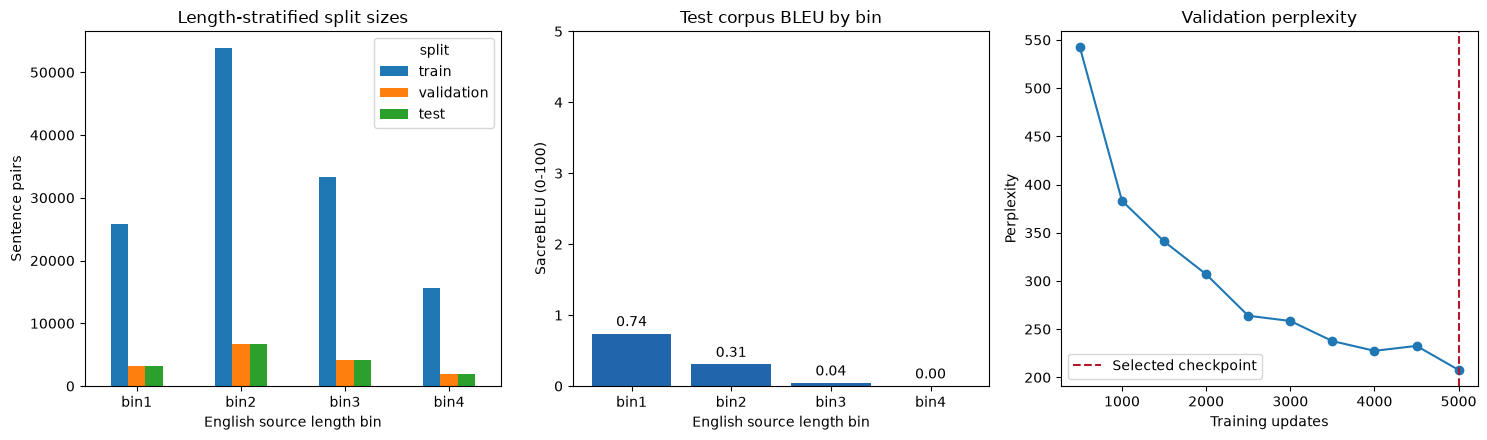

## Observed results

Overall BLEU: **0.130**.

BLEU is very low across this experiment. This small model and training budget provide an executable baseline, but do not achieve useful translation accuracy. The strongest bin is only strongest relative to the other bins, not a high-quality translation result.

The complete hypotheses contain 96,377 SacreBLEU tokens against 347,288 reference tokens, a ratio of 0.278. The overall brevity penalty is 0.074.

The large aggregate length deficit is evidence of severe undertranslation. The displayed examples include generic Hindi phrases that omit most source information. Teacher-forced validation improvement therefore did not translate into adequate sentence-level generation. A larger training budget, validation-based checks of decoded translations, and a stronger model are justified follow-up experiments; their settings should be chosen on validation data.

In this run, BLEU decreases with each successive source-length bin. Read the brevity penalties and length ratios beside the scores: the output-length deficit also becomes more severe for long inputs.

- **bin1 (L <= 10):** BLEU 0.739 on 3232 test pairs, with 25856 training pairs. Output/reference token ratio 0.608; brevity penalty 0.525. Short outputs suggest inspecting omitted phrases and premature endings.
- **bin2 (11 <= L <= 19):** BLEU 0.306 on 6729 test pairs, with 53836 training pairs. Output/reference token ratio 0.365; brevity penalty 0.175. Short outputs suggest inspecting omitted phrases and premature endings.
- **bin3 (20 <= L <= 29):** BLEU 0.044 on 4165 test pairs, with 33320 training pairs. Output/reference token ratio 0.211; brevity penalty 0.024. Short outputs suggest inspecting omitted phrases and premature endings.
- **bin4 (L >= 30):** BLEU 0.002 on 1949 test pairs, with 15593 training pairs. Output/reference token ratio 0.121; brevity penalty 0.001. Short outputs suggest inspecting omitted phrases and premature endings.

Saved report: C:\Users\Tanu Meena\OneDrive\Desktop\llm\Lab8\assignment8_artifacts\assignment8_report.md
Saved predictions: C:\Users\Tanu Meena\OneDrive\Desktop\llm\Lab8\assignment8_artifacts\test_predictions.csv
Saved bin-wise BLEU: C:\Users\Tanu Meena\OneDrive\Desktop\llm\Lab8\assignment8_artifacts\bin_wise_bleu.csv


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
counts = summary.pivot(index="bin", columns="split", values="sentences").reindex(BINS)
counts[["train", "validation", "test"]].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Length-stratified split sizes", xlabel="English source length bin",
            ylabel="Sentence pairs")
bin_scores = bleu_results.loc[bleu_results.bin.isin(BINS)].set_index("bin").reindex(BINS)
bars = axes[1].bar(BINS, bin_scores.BLEU, color="#2166ac")
axes[1].bar_label(bars, fmt="%.2f", padding=3)
axes[1].set(title="Test corpus BLEU by bin", xlabel="English source length bin",
            ylabel="SacreBLEU (0-100)", ylim=(0, max(5, float(bin_scores.BLEU.max()) * 1.2)))
axes[2].plot(validation_history.step, validation_history.validation_perplexity, marker="o")
axes[2].axvline(selected_step, color="#b2182b", linestyle="--", label="Selected checkpoint")
axes[2].set(title="Validation perplexity", xlabel="Training updates", ylabel="Perplexity")
axes[2].legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "assignment8_evaluation.png", dpi=170, bbox_inches="tight")
plt.show()

strongest = bin_scores.BLEU.idxmax()
weakest = bin_scores.BLEU.idxmin()
overall_bleu = float(bleu_results.loc[bleu_results.bin == "overall", "BLEU"].iloc[0])
overall_row = bleu_results.loc[bleu_results.bin == "overall"].iloc[0]
quality_notes = []
if overall_bleu < 5:
    quality_notes.append(
        "BLEU is very low across this experiment. This small model and training "
        "budget provide an executable baseline, but do not achieve useful "
        "translation accuracy. The strongest bin is only strongest relative "
        "to the other bins, not a high-quality translation result.")
quality_notes.append(
    f"The complete hypotheses contain {int(overall_row.hypothesis_tokens):,} "
    f"SacreBLEU tokens against {int(overall_row.reference_tokens):,} reference "
    f"tokens, a ratio of {overall_row.length_ratio:.3f}. The overall brevity "
    f"penalty is {overall_row.brevity_penalty:.3f}.")
if overall_row.length_ratio < 0.5:
    quality_notes.append(
        "The large aggregate length deficit is evidence of severe "
        "undertranslation. The displayed examples include generic Hindi "
        "phrases that omit most source information. Teacher-forced validation "
        "improvement therefore did not translate into adequate sentence-level "
        "generation. A larger training budget, validation-based checks of "
        "decoded translations, and a stronger model are justified follow-up "
        "experiments; their settings should be chosen on validation data.")
if np.all(np.diff(bin_scores.BLEU.to_numpy()) <= 0):
    quality_notes.append(
        "In this run, BLEU decreases with each successive source-length bin. "
        "Read the brevity penalties and length ratios beside the scores: "
        "the output-length deficit also becomes more severe for long inputs.")
quality_analysis = "\n\n".join(quality_notes)
training_counts = counts["train"].to_dict()
analysis = []
for bin_name in BINS:
    row = bin_scores.loc[bin_name]
    text = (f"- **{bin_name} ({BIN_LABELS[bin_name]}):** BLEU {row.BLEU:.3f} on "
            f"{int(row.sentences)} test pairs, with {int(training_counts[bin_name])} "
            f"training pairs. Output/reference token ratio {row.length_ratio:.3f}; "
            f"brevity penalty {row.brevity_penalty:.3f}.")
    if row.length_ratio < 0.9:
        text += " Short outputs suggest inspecting omitted phrases and premature endings."
    elif row.length_ratio > 1.1:
        text += " Long outputs suggest inspecting repetitions or added content."
    else:
        text += " Aggregate output length is close to reference length; inspect word choice and order."
    analysis.append(text)
example_records = []
for bin_name in BINS:
    example_row = predictions.loc[predictions.bin == bin_name].iloc[0]
    example_records.append(f"### {bin_name}\n\nEnglish: {example_row.source}\n\n"
                           f"Reference Hindi: {example_row.target}\n\n"
                           f"Predicted Hindi: {example_row.prediction}\n")
report = f"""# Assignment 8 - English-to-Hindi Machine Translation

Name: Tanu Meena  
Roll number: U23AI076

## Experiment

OpenNMT-py 3.5.1 trains a two-layer encoder/two-layer decoder Transformer from
scratch using BPCC's ILCI English-Hindi pairs. Embedding/hidden size is 128,
four attention heads, feed-forward size 512, dropout 0.1, label smoothing 0.1,
Adam with Noam scheduling, batch size 1,024 tokens, and {TRAIN_STEPS:,} updates.
The complete cleaned dataset is used. Separate English and Hindi SentencePiece
BPE tokenizers, up to {SUBWORD_VOCAB_SIZE:,} pieces each, use training data only.

## Data and split

Dataset: https://huggingface.co/datasets/{DATASET_ID}  
Requested revision: `{DATASET_REVISION}`  
Subset: `{DATASET_FILE}`  
Raw SHA-256: `{data_manifest['raw_sha256']}`

Length is English whitespace word count before BPE. Within each of four bins,
80/10/10 train/validation/test allocation is used with seed {SEED}, subject to
rounding. The omitted boundary L=20 is assigned to bin3. Exact pair, source, and
target duplicates are removed before splitting, preventing exact-text leakage.
Alternative translations for repeated sources are discarded by this policy.

Cleaning audit:

{pd.DataFrame([cleaning_audit]).to_markdown(index=False)}

Split distribution:

{summary.round(2).to_markdown(index=False)}

## Model selection and evaluation

Selected checkpoint: `{selected_model.name}` at step {selected_step:,}, validation
perplexity {best_row.validation_perplexity:.4f}. Selection uses minimum validation
perplexity. Test scores do not select the checkpoint. Training time:
{completion['elapsed_seconds'] / 60:.2f} minutes. Decoding uses beam size 5,
Wu length penalty alpha 0.6, maximum output length {max_decode_length} BPE pieces
(determined from training targets). OpenNMT receives no test references to decode.

Predictions are detokenized Hindi. The score is case-sensitive corpus BLEU with
13a tokenization, exponential smoothing, standard four n-gram orders, one
reference, and a 0-100 scale. Overall BLEU is computed on the full test corpus.

Signature: `{bleu_records[-1]['signature']}`

{bleu_results[['bin', 'length_range', 'sentences', 'BLEU', 'brevity_penalty', 'length_ratio']].round(3).to_markdown(index=False)}

## Bin-wise result analysis

Overall test BLEU is **{overall_bleu:.3f}**. The strongest observed bin is
**{strongest}** ({bin_scores.loc[strongest, 'BLEU']:.3f}); the weakest is
**{weakest}** ({bin_scores.loc[weakest, 'BLEU']:.3f}).

{quality_analysis}

{chr(10).join(analysis)}

Scores should be assessed alongside the unequal training/test counts. With a
small model and finite training budget, long sequences can accumulate decoding
errors, but a length-related decline is not guaranteed. Bin membership itself
does not prove the cause of an error. A low brevity penalty identifies short
translations as one possible contributor. Single-reference BLEU can undercount
valid paraphrases. Qualitative checks should examine omissions, repetition,
Hindi word order, agreement, and domain-specific terminology. Improved models
can be compared on these same saved splits; select their settings using validation.

## One actual test translation per bin

{chr(10).join(example_records)}

## References to earlier assignments

- Assignment 3: source-word length-aware held-out sampling and training subword
  models from scratch. This lab uses the four explicit ranges instead of quantiles.
- Assignment 4: word counts and separate validation/test evaluation.
- Assignments 6 and 7: reproducible settings, checkpoints, per-group metrics,
  prediction files, plots, and an observed-result report.
- Prior IndicCorpV2 data is monolingual, so it is not substituted for ILCI bitext.

## References

- Supplied ILLM-Lab8-Assignment.pdf.
- OpenNMT-py: https://github.com/OpenNMT/OpenNMT-py
- BPCC: https://huggingface.co/datasets/ai4bharat/BPCC
- SacreBLEU: https://github.com/mjpost/sacrebleu
- SentencePiece: https://github.com/google/sentencepiece
"""
(OUTPUT_DIR / "assignment8_report.md").write_text(report, encoding="utf-8")
display(Markdown("## Observed results\n\n" + f"Overall BLEU: **{overall_bleu:.3f}**.\n\n"
                 + quality_analysis + "\n\n" + "\n".join(analysis)))
print("Saved report:", OUTPUT_DIR / "assignment8_report.md")
print("Saved predictions:", OUTPUT_DIR / "test_predictions.csv")
print("Saved bin-wise BLEU:", OUTPUT_DIR / "bin_wise_bleu.csv")

## Assignment 8 checklist

- English source and Hindi target, using the required BPCC ILCI subset.
- Four explicit source-word length bins with the L=20 decision documented.
- Stratified train/validation/test splits; all four bins occur in every split.
- Cleaning audit, original row IDs, split hashes, and exact-text overlap checks.
- Training-only BPE tokenizers and OpenNMT vocabularies.
- A neural translation model trained with the real OpenNMT-py library.
- Validation-only checkpoint selection and beam-search test translations.
- Detokenized overall and per-bin corpus BLEU from SacreBLEU, with signatures.
- Actual predictions, score tables, plots, and automatically generated analysis.

The code implements the complete workflow. Numerical results exist only after
dataset access, training, translation, and evaluation have successfully finished.